# Asignación de deliberación: fundamentos

**Nivel:** 1  
**Requisitos previos:** 03-sequential-control  
**Tiempo de lectura:** 15 minutos

**Pregunta:** ¿Qué muestra la evidencia congelada C13 sobre decisiones del planificador, delegación y demora medida?


## Objetivos

Para el nivel 1 de asignación de deliberación en C13, Separa la decisión rápida de una llamada opcional al planificador. Para el nivel 1 de asignación de deliberación en C13, Delegar solo sirve si el cambio en el resultado verificado independientemente compensa la demora, las propuestas inválidas y el trabajo no utilizado bajo el mismo estado observado de candidatos.


## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
Para el nivel 1 de asignación de deliberación en C13, El notebook lee artefactos comprometidos del producto. Para el nivel 1 de asignación de deliberación en C13, Propietario: Para el nivel 1 de asignación de deliberación en C13, Neuraxis. Para el nivel 1 de asignación de deliberación en C13, Repositorio: Para el nivel 1 de asignación de deliberación en C13, https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Para el nivel 1 de asignación de deliberación en C13, Apache-2.0. Para el nivel 1 de asignación de deliberación en C13, El JSON es un artefacto experimental propio y congelado; Para el nivel 1 de asignación de deliberación en C13, este notebook no redistribuye datos de benchmarks externos.

Para el nivel 1 de asignación de deliberación en C13, Este notebook lee `data/derived/index.json` y las trazas listadas. Para el nivel 1 de asignación de deliberación en C13, La ejecución usa un espacio aislado de caso Reflexmesh. Para el nivel 1 de asignación de deliberación en C13, Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta. Para el nivel 1 de asignación de deliberación en C13, El manifiesto de publicación verifica los hashes. Para el nivel 1 de asignación de deliberación en C13, M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado.

Para el nivel 1 de asignación de deliberación en C13, Artefactos de esta lección:

- `data/derived/index.json`
- `data/derived/semantic-routing-study/analysis.json`
- `data/derived/episodes/M11-C13-nominal-40000.json`
- `data/derived/episodes/M12-C13-nominal-40000.json`
- `data/derived/episodes/M09-C13-nominal-40000.json`
- `data/derived/episodes/M10-C13-nominal-40000.json`


## Método

Para el nivel 1 de asignación de deliberación en C13, Separa la decisión rápida de una llamada opcional al planificador. Para el nivel 1 de asignación de deliberación en C13, Delegar solo sirve si el cambio en el resultado verificado independientemente compensa la demora, las propuestas inválidas y el trabajo no utilizado bajo el mismo estado observado de candidatos. Para el nivel 1 de asignación de deliberación en C13, En este ejercicio de nivel 1 sobre asignación de deliberación, sigue solo la primera decisión y la poscondición verificada independientemente. Para el nivel 1 de asignación de deliberación en C13, La llamada construye la política publicada y el evaluador avanza el entorno de software. Para el nivel 1 de asignación de deliberación en C13, La regla de autorización sigue separada de la preferencia, así que detenerse o fallar también puede ser un resultado válido cuando no existe una acción respaldada. Para el nivel 1 de asignación de deliberación en C13, En el nivel 1, para asignación de deliberación en C13, Una puerta de delegación compara el valor esperado de la respuesta lenta con el resultado verificado de la política rápida, incluida la latencia, propuestas inválidas y razonamiento sin uso. Para el nivel 1 de asignación de deliberación en C13, En el nivel 1, para asignación de deliberación en C13, Las trazas C13 muestran cuándo el controlador experimental pidió deliberación, pero una reproducción no demuestra que un modelo activo responda bien con contexto modificado.


### asignación de deliberación · nivel 1 — Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.


In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M11", "M12", "M09", "M10"]
trace_methods = ["M11", "M12", "M09", "M10"]
sample_case = "C13"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 4


### asignación de deliberación · L1 — Construir la primera política ejecutable

En el nivel 1, construye M01 para asignación de deliberación con la fábrica pública y conserva su contrato de observación antes de muestrear C13.


In [3]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = "M01"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M01


### asignación de deliberación · L1 — Ejecutar el método principal en el caso indicado

En el nivel 1 de asignación de deliberación, el evaluador ejecuta M01 en C13 y deriva el éxito de la poscondición independiente, no de una traza reproducida.


In [4]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### asignación de deliberación · L1 — Construir una política de comparación independiente

Para el nivel 1 de asignación de deliberación, crea M02 como objeto nuevo para impedir que el estado recurrente de M01 contamine la comparación.


In [5]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = "M02"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M02


### asignación de deliberación · L1 — Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 1 ejecuta M02 en el mismo C13, variante nominal y semilla, and ilustra comportamiento, no estima una tasa poblacional.


In [6]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### asignación de deliberación · L1 — Agregar los dos episodios ejecutados

En el nivel 1, el agregador resume dos episodios ejecutados de asignación de deliberación, and las afirmaciones entre familias aún requieren el benchmark completo.


In [7]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### asignación de deliberación · L1 — Resultados de políticas nuevas

Para el nivel 1 de asignación de deliberación en C13, El gráfico siguiente se calcula con los resultados de episodios de asignación de deliberación recién ejecutados en C13, no se copia de un artefacto congelado.


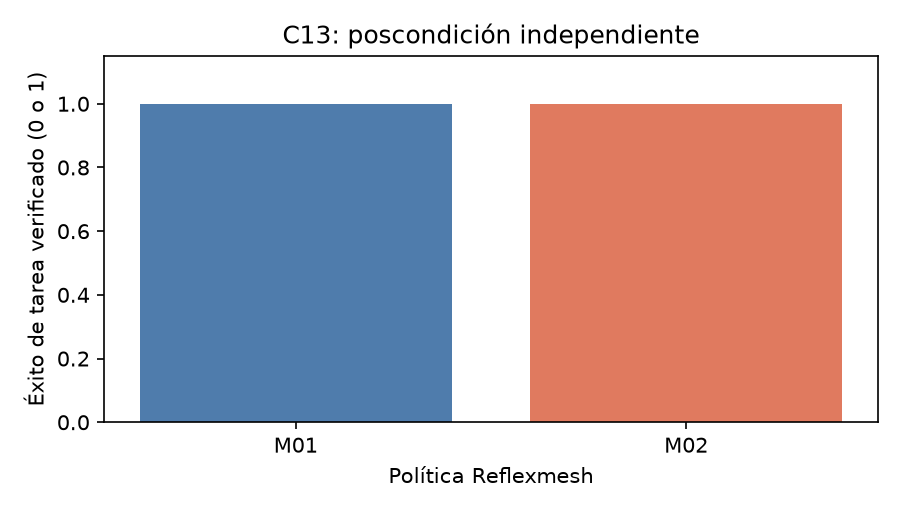

In [8]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Éxito de tarea verificado (0 o 1)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: poscondición independiente")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para el nivel 1 de asignación de deliberación en C13, Para asignación de deliberación, estas barras muestran resultados nuevos de poscondición de M01 y M02 en C13; Para el nivel 1 de asignación de deliberación en C13, éxito vale 1 y falla 0. Para el nivel 1 de asignación de deliberación en C13, Lee el caso y la semilla antes de compararlas. Para el nivel 1 de asignación de deliberación en C13, Este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software.


## Resultados

**Respuesta:** El ejemplo de asignación de deliberación ejecuta 2 políticas, M01 y M02, en C13; la muestra emparejada demuestra la API y la verificación independiente, no el rendimiento del benchmark.

Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, El ajuste de la puerta usó 228 estados con siete etiquetas positivas y seleccionó el umbral 1,01, por lo que nunca delegó a través de esa puerta. Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, El otro disparador de M12 es independiente. Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Informa llamadas al planificador, latencia y éxito verificado; Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, configurar un LLM no demuestra que deliberar sea útil.

Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Este paso de autoría no compromete salidas generadas; Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, Para el nivel 1 de asignación de deliberación en C13, `scripts/run_notebooks.py` las ejecuta y guarda desde un kernel nuevo.


## Resumen

Para el nivel 1 de asignación de deliberación en C13, En el nivel 1, asignación de deliberación usa C13 para mostrar el comportamiento del método publicado bajo una condición declarada. Para el nivel 1 de asignación de deliberación en C13, Mantén el resultado observado separado de una afirmación sobre inteligencia general para controlar software.


## Referencias

- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev)
- [DPT](https://aclanthology.org/2025.acl-long.206/)
- [VOC](https://arxiv.org/abs/1711.06892)
- [DEFER](https://proceedings.mlr.press/v119/mozannar20b.html)
